# Contamination experiments: clean one-class TimesNet vs benign train + 10% of one attack

Test AUROC of the clean run `model-t32b-seed0` (benign train) next to the four mix10 runs (benign train + 10% of
GridSybil / DataReplay / DoSRandom / DoSDisruptive; same config, seed, test windows), for each test attack × score
(reconstruction, Mahalanobis, kNN k5), pretrained vs random-init, with the length-only reference. Reads only the
`summary.json` of each evaluation folder (scores saved before labels were read, by `evaluate.py`); models whose
evaluation is missing are listed and left out. Spec: `src/model/all_t32_benign/experiments/README.md`. One seed per
model: differences are not results until seeds 1, 2 exist.

Settings (`SUBSET`: `all`, `n_ge_2` or `n_ge_4` real rows; the reconstruction AUROC on `all` depends on the fill of < 2-row windows, so n ≥ 2 is the default).

In [1]:
import os

SEED = int(os.environ.get("MIX10_SEED", "0"))
SUBSET = os.environ.get("MIX10_SUBSET", "n_ge_2")
MIXES = ("gridsybil", "datareplay", "dosrandom", "dosdisruptive")
CLEAN_EVAL = os.environ.get("MIX10_CLEAN_EVAL") or "src/runs/evaluation/all/T32_benign/model-t32b-seed0"
CLEAN_RUN = os.environ.get("MIX10_CLEAN_RUN") or "src/runs/pretraining/all/T32_benign/model-t32b-seed0"

In [2]:
import json
from pathlib import Path

assert Path("CLAUDE.md").is_file() and Path("src/model/all_t32_benign").is_dir(), "run from the repo root"

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.model.all_t32_benign.timesnet import plots

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
SCORES = ("recon", "mahalanobis", "knn_k5")
FINISHED_REASONS = ("max_epochs", "early_stopping")
# fixed categorical order (colour follows the model, never its rank)
COLORS = {"clean": "#2a78d6", "gridsybil": "#eb6834", "datareplay": "#1baf7a", "dosrandom": "#eda100",
          "dosdisruptive": "#e87ba4"}

MODELS = {"clean": (CLEAN_RUN, CLEAN_EVAL)}
for a in MIXES:
    rid = f"model-t32m10-{a}-seed{SEED}"
    MODELS[a] = (f"src/runs/pretraining/all/T32_mix10_{a}/{rid}", f"src/runs/evaluation/all/T32_mix10_{a}/{rid}")


def read(path):
    p = Path(path) / "summary.json"
    return json.loads(p.read_text()) if p.is_file() else None


status, rows = [], []
for model, (run_dir, eval_dir) in MODELS.items():
    rs = read(run_dir)
    st = {"model": model, "run": run_dir, "run summary": rs is not None,
          "finished": bool(rs) and rs.get("stop_reason") in FINISHED_REASONS,
          "stop_reason": rs.get("stop_reason") if rs else None, "best_epoch": rs.get("best_epoch") if rs else None,
          "best_val_joint": rs.get("best_val_joint") if rs else None}
    for init, folder in (("pretrained", eval_dir), ("random-init", eval_dir + "-random-init")):
        es = read(folder)
        st[f"{init} eval"] = es is not None and not es.get("smoke")
        if es is None or es.get("smoke"):
            continue
        df = plots.AurocTable.long(es)
        df = df[df.score.isin((*SCORES, "length_only"))]
        for _, r in df.iterrows():
            rows.append({"model": model, "init": init, "attack": r.attack, "score": r.score, "subset": r.subset,
                         "AUROC": r.AUROC})
    status.append(st)
status = pd.DataFrame(status).set_index("model")
display(status)
long = pd.DataFrame(rows)
if long.empty:
    print("*** no evaluation found yet: nothing to compare (run mix10_eval.sh <attack>) ***")

,run,run summary,finished,stop_reason,best_epoch,best_val_joint,pretrained eval,random-init eval
model,,,,,,,,
clean,src/runs/pretraining/all/T32_benign/model-t32b...,True,True,max_epochs,20,0.314156,True,True
gridsybil,src/runs/pretraining/all/T32_mix10_gridsybil/m...,True,True,max_epochs,20,0.327514,True,True
datareplay,src/runs/pretraining/all/T32_mix10_datareplay/...,True,True,max_epochs,20,0.305699,True,True
dosrandom,src/runs/pretraining/all/T32_mix10_dosrandom/m...,True,True,max_epochs,19,0.276753,True,True
dosdisruptive,src/runs/pretraining/all/T32_mix10_dosdisrupti...,True,True,max_epochs,19,0.292132,True,True


Table: AUROC per model × init (rows) and test attack × score (columns) on `SUBSET`; then Δ vs the clean run (same init).

In [3]:
if not long.empty:
    sub = long[(long.subset == SUBSET) & (long.score != "length_only")]
    table = sub.pivot_table(index=["model", "init"], columns=["attack", "score"], values="AUROC", sort=False)
    order = [m for m in MODELS if m in table.index.get_level_values(0)]
    table = table.reindex(order, level=0)
    print(f"subset {SUBSET}")
    display(table.round(3))
    if "clean" in table.index.get_level_values(0):
        delta = table.sub(table.xs("clean", level="model"), level="init").drop(index="clean", level="model")
        print("Δ vs clean (same init)")
        display(delta.round(3))
    length = long[(long.subset == SUBSET) & (long.score == "length_only") & (long.init == "pretrained")]
    print("length-only AUROC on the same windows (per model; should be equal across models):")
    display(length.pivot_table(index="model", columns="attack", values="AUROC", sort=False).round(3))

subset n_ge_2


attack                    GridSybil                    DataReplay                    DoSRandom                    DoSDisruptive                   
score                         recon mahalanobis knn_k5      recon mahalanobis knn_k5     recon mahalanobis knn_k5         recon mahalanobis knn_k5
model         init                                                                                                                                
clean         pretrained      0.760       0.888  0.894      0.469       0.934  0.889     0.999       0.997  0.999         0.997       0.997  0.997
              random-init     0.559       0.674  0.840      0.434       0.908  0.882     0.998       0.996  0.990         0.976       0.993  0.946
gridsybil     pretrained      0.689       0.747  0.785      0.486       0.926  0.875     0.999       0.999  1.000         0.998       0.997  0.996
              random-init     0.537       0.649  0.775      0.442       0.906  0.874     0.999       0.996  0.996         0.976       0.994  0.963
datareplay    pretrained      0.753       0.883  0.891      0.360       0.888  0.707     0.998       0.992  0.996         0.996       0.995  0.981
              random-init     0.559       0.670  0.837      0.435       0.859  0.722     0.998       0.996  0.990         0.976       0.994  0.931
dosrandom     pretrained      0.758       0.884  0.894      0.476       0.927  0.888     0.973       0.728  0.359         0.996       0.965  0.943
              random-init     0.557       0.665  0.838      0.435       0.899  0.885     0.998       0.954  0.810         0.976       0.969  0.947
dosdisruptive pretrained      0.758       0.888  0.895      0.714       0.932  0.904     0.994       0.963  0.930         0.968       0.952  0.815
              random-init     0.553       0.667  0.838      0.437       0.894  0.880     0.998       0.983  0.968         0.976       0.945  0.803

Δ vs clean (same init)


attack                    GridSybil                    DataReplay                    DoSRandom                    DoSDisruptive                   
score                         recon mahalanobis knn_k5      recon mahalanobis knn_k5     recon mahalanobis knn_k5         recon mahalanobis knn_k5
model         init                                                                                                                                
gridsybil     pretrained     -0.071      -0.141 -0.109      0.017      -0.008 -0.014     0.001       0.002  0.001         0.000       0.001 -0.001
              random-init    -0.022      -0.025 -0.065      0.007      -0.002 -0.008     0.000       0.000  0.006         0.000       0.001  0.017
datareplay    pretrained     -0.007      -0.005 -0.003     -0.109      -0.046 -0.183    -0.000      -0.004 -0.003        -0.001      -0.002 -0.016
              random-init    -0.000      -0.004 -0.003      0.000      -0.049 -0.159     0.000       0.000 -0.000        -0.000       0.001 -0.016
dosrandom     pretrained     -0.002      -0.004  0.000      0.007      -0.008 -0.001    -0.026      -0.269 -0.640        -0.001      -0.032 -0.053
              random-init    -0.002      -0.009 -0.002      0.001      -0.009  0.003     0.000      -0.042 -0.180         0.000      -0.024  0.000
dosdisruptive pretrained     -0.002       0.001  0.001      0.244      -0.002  0.015    -0.004      -0.033 -0.068        -0.030      -0.045 -0.181
              random-init    -0.006      -0.007 -0.002      0.003      -0.014 -0.002     0.000      -0.013 -0.022         0.000      -0.048 -0.143

length-only AUROC on the same windows (per model; should be equal across models):


attack,GridSybil,DataReplay,DoSRandom,DoSDisruptive
model,,,,
clean,0.549,0.947,0.964,0.964
gridsybil,0.549,0.947,0.964,0.964
datareplay,0.549,0.947,0.964,0.964
dosrandom,0.549,0.947,0.964,0.964
dosdisruptive,0.549,0.947,0.964,0.964


Bar chart: one panel per score (rows) × test attack (columns); bars = models in fixed colours, solid = pretrained, hatched light = random-init; dashed line = length only.

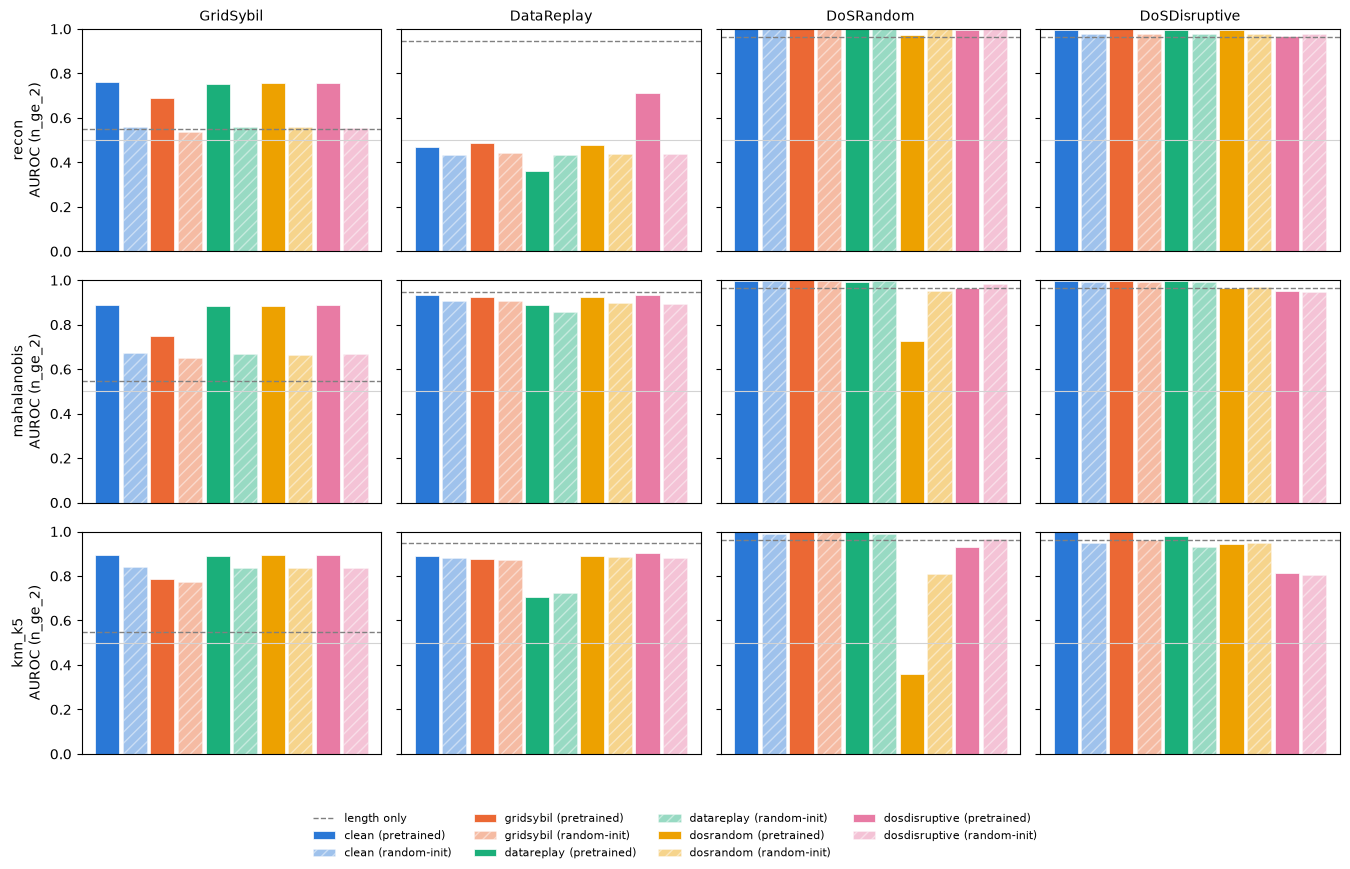

In [4]:
if not long.empty:
    sub = long[long.subset == SUBSET]
    attacks = [a for a in plots.ATTACKS.values() if a in set(sub.attack)]
    models = [m for m in MODELS if m in set(sub.model)]
    fig, axes = plt.subplots(len(SCORES), len(attacks), figsize=(3.4 * len(attacks), 2.9 * len(SCORES)),
                             sharey=True, squeeze=False)
    width = 0.8 / max(len(models), 1)
    for i, score in enumerate(SCORES):
        for j, attack in enumerate(attacks):
            ax = axes[i][j]
            for k, m in enumerate(models):
                for init, off, kw in (("pretrained", -width / 4, {}),
                                      ("random-init", width / 4, {"alpha": 0.45, "hatch": "///"})):
                    v = sub[(sub.model == m) & (sub.init == init) & (sub.score == score) & (sub.attack == attack)]
                    if len(v):
                        ax.bar(k * width + off, v.AUROC.iloc[0], width / 2 - 0.01, color=COLORS[m],
                               edgecolor="white", linewidth=0.5,
                               label=f"{m} ({init})" if (i, j) == (0, 0) else None, **kw)
            ln = sub[(sub.score == "length_only") & (sub.attack == attack) & (sub.init == "pretrained")]
            if len(ln):
                ax.axhline(ln.AUROC.iloc[0], color="grey", ls="--", lw=1,
                           label="length only" if (i, j) == (0, 0) else None)
            ax.axhline(0.5, color="lightgrey", lw=0.8)
            ax.set_xticks([])
            ax.set_ylim(0, 1)
            if i == 0:
                ax.set_title(attack, fontsize=10)
            if j == 0:
                ax.set_ylabel(f"{score}\nAUROC ({SUBSET})")
    fig.legend(loc="lower center", ncol=4, fontsize=8, frameon=False)
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()

## Reading

*Template, fill only from the tables above:* for each mix, the AUROC of its own attack vs clean (Δ, pretrained and
random-init), the effect on the other attacks, and whether any difference exceeds what seeds would vary (unknown until
seeds 1, 2). Caveats: one seed each; F11 (DataReplay / DoS separated by length); the mixes are also normalised
differently, which affects the random-init control too.